# 2026 ATP/WTA：比赛负荷与胜率

**状态：本文件已在本地验证；当前运行平台见 execution 输出，云端完成状态以 Kaggle 版本日志为准。**

冻结 TML 2026-10-22 数据；接入 TennisStats 官方演示及 10 月 23 日公开赛程。仅用于私人研究。导入 Kaggle 私人 Notebook，CPU → Run All；无需联网。

研究的是同届前序正赛累计用时的关联。日期语义混合，因此不计算休息天数，不作疲劳因果结论。

In [1]:
from pathlib import Path
import base64, io, zipfile, sys, json
ROOT = Path.cwd() / "tennis_project"
ROOT.mkdir(exist_ok=True)
payload = "..."
with zipfile.ZipFile(io.BytesIO(base64.b64decode(payload))) as z:
    for member in z.namelist():
        if not (ROOT/member).resolve().is_relative_to(ROOT.resolve()):
            raise ValueError("Unsafe archive member")
    z.extractall(ROOT)
sys.path.insert(0, str(ROOT))
print("Frozen project extracted:", ROOT)


Frozen project extracted: /kaggle/working/tennis_project


## 清洗、赛前特征和时间验证

训练：一月至六月；验证：七月至八月；测试：九月起赛事。较早数据划分留 21 天赛事缓冲。两种模型独立选择正则化强度，不在测试集调参。

原始 winner/loser 被转成稳定球员顺序。仅在同一轮全部完成特征后，再把该轮结果写入历史。

In [2]:
import analysis
report = analysis.run(ROOT, reps=500)


{
  "audit": {
    "raw_rows": 5055,
    "duplicates": 1,
    "season_2026_raw": 5054,
    "completed_standard_2026": 4874,
    "primary_samples": 1578,
    "train": 887,
    "validation": 187,
    "test": 174,
    "purged_boundary_samples": 330,
    "purge_days": 21,
    "test_events": 16,
    "date_semantics": "mixed match-day / tournament start; event-round history only",
    "cutoff": "2026-10-22 snapshot",
    "ineligible_2026_knockout": 3233
  },
  "metrics": [
    {
      "model": "strength",
      "C": 0.1,
      "n": 174,
      "accuracy": 0.6091954022988506,
      "auc": 0.6712765957446809,
      "log_loss": 0.6512330476932024,
      "brier": 0.22973968989863283
    },
    {
      "model": "strength_workload",
      "C": 0.01,
      "n": 174,
      "accuracy": 0.6091954022988506,
      "auc": 0.6602393617021276,
      "log_loss": 0.6572026522390292,
      "brier": 0.23231853049455384
    }
  ],
  "comparison": {
    "delta_log_loss": 0.005969604545826789,
    "ci95": [
      

## 泄漏与数据契约检查

修改未来决赛用时不得影响任何本场或此前轮次特征；交换双方概率应互补；完整赛季请求不能误用 demo key。

In [3]:
exec(compile((ROOT/"test_pipeline.py").read_text(), str(ROOT/"test_pipeline.py"), "exec"), {"__file__": str(ROOT/"test_pipeline.py"), "__name__": "__tests__"})


PASS: score validation, no same/future-round workload leakage, swap symmetry, demo schema, demo access boundary


## TennisStats 接入与冻结赛前预测

将已核验的 TennisStats 公开对阵及当前排名，与 TML 的赛事、姓名和前轮获胜记录匹配。API 示例 971951 另做比分与身份交叉校验。预测模型在独立评估结束后才使用全部合格 2026 数据重拟合。

In [4]:
from predict_fixtures import generate
forecasts = generate(ROOT)


   event            name_a            name_b  prior_hours_a  prior_hours_b  p_a_strength  p_a_strength_workload
    Lyon   Corentin Moutet        Tommy Paul       4.816667       2.100000      0.274119               0.284759
    Lyon    Flavio Cobolli Brandon Nakashima       1.133333       3.500000      0.643423               0.644667
Brussels Tallon Griekspoor      Jiri Lehecka       4.050000       1.316667      0.328392               0.322957
  Ningbo         Iva Jovic    Diana Shnaider       1.366667       4.350000      0.530955               0.578300
{
  "official_api_demo_reconciled": true,
  "tennisstats_match_id": 971951,
  "tml_event": "ATP:2026-410",
  "sets": 2,
  "games": 22,
  "tml_minutes": 135.0,
  "full_tennisstats_history_loaded": false,
  "fixture_rows_joined": 4,
  "provider_ids_are_distinct": true
}


## 结果图

准确率未提升；Log loss 差异区间跨零。系数区间是探索性惩罚模型的赛事重采样区间，不能解释为因果效应。

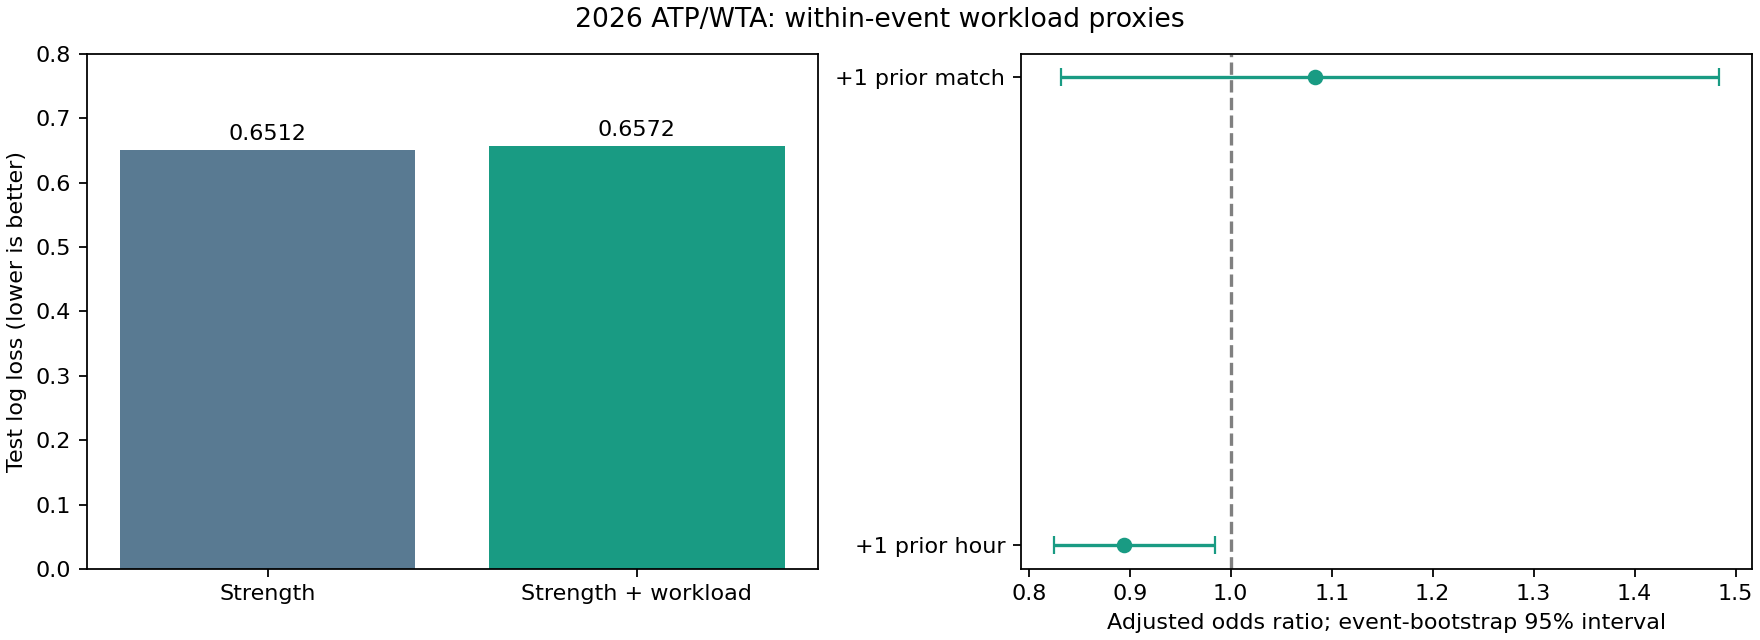

In [5]:
try:
    from IPython.display import display, Image
    display(Image(filename=str(ROOT/"outputs/results.png")))
except ImportError:
    print("Chart saved:", ROOT/"outputs/results.png")


## 可选：连接自己的 TennisStats 全量历史

在 Kaggle Secrets 添加 `TENNISSTATS_API_KEY`，保持 Notebook 私有。将下面开关改成 True 才会访问账户 API。`testkey` 不提供完整历史。

输出中的时间是计划开赛时间，文档列表不含用时。先核验完整性和跨来源身份，再扩展为休息时间模型；此导出不会自动覆盖已验证的 TML 分析。

In [6]:
RUN_FULL_API_EXPORT = False
if RUN_FULL_API_EXPORT:
    from tennisstats_client import TennisStats, export_seasons
    print(export_seasons(TennisStats(cache=ROOT/"private_api_cache"), ROOT/"tennisstats_export", years=(2025,2026)))
else:
    print("Account API export skipped; no credentials required for frozen reproduction.")


Account API export skipped; no credentials required for frozen reproduction.


## 文件与来源

结果保存在 `tennis_project/outputs`：球员统计、比赛样本排除原因、逐场赛前特征、174 场测试预测、4 场冻结未来预测、模型系数与训练摘要。

[TML 数据说明](https://stats.tennismylife.org/tennis-match-database) · [TennisStats](https://tennisstats.com/) · [API 文档](https://tennisstats.com/api/documentations)

详细假设、来源条件和复现说明见内嵌 `README_zh.txt`。不使用网站的全年事后统计训练历史赛前预测。